![Banner](../../../../Images/Banner/05_geostat/08_bayesian_kriging.png)

# Bayesian Kriging (`BayesianKriging`)

**Dataset:** Jura soil survey, Swiss Jura (`Data/00_shared/data_geostatistics/jura_data.csv`, 359 samples) + prediction grid (`Data/00_shared/data_geostatistics/jura_grid.csv`, 5,957 nodes on a 50 m lattice; a 100 m subset of 1,540 nodes is used for maps)

**Target:** cadmium (`Cd`, mg/kg), modelled on the log scale; raw Cd for the transformed model; the indicator `Cd > 0.8 mg/kg` for the binomial model

**Library:** `geolattice.geostatistics`: `BayesianKriging`, `ConjugateBayesianKriging`, `BayesianTransformedKriging`, `BayesianGLMKriging`, `bayesian_kriging`, `correlation_function` (module `geolattice.geostatistics.kriging.bayesian_kriging`)

**Before this notebook:** [Empirical Bayesian kriging](05_08_01_empirical_bayesian_kriging.ipynb), which uses the same data and split, and [ordinary kriging](../05_02_kriging/05_02_02_ordinary_kriging.ipynb).

***

## Table of Contents

1. [Overview](#overview)
2. [Theory](#theory)
    - 2.1 [The model](#the-model)
    - 2.2 [Priors](#priors)
    - 2.3 [The conjugate posterior for a fixed correlation](#the-conjugate-posterior-for-a-fixed-correlation)
    - 2.4 [The marginal likelihood of the correlation parameters](#the-marginal-likelihood-of-the-correlation-parameters)
    - 2.5 [The grid posterior and the predictive mixture](#the-grid-posterior-and-the-predictive-mixture)
    - 2.6 [Signal or observation, and joint simulation](#signal-or-observation-and-joint-simulation)
    - 2.7 [Transformed Gaussian kriging](#transformed-gaussian-kriging)
    - 2.8 [Generalized linear kriging by MCMC](#generalized-linear-kriging-by-mcmc)
    - 2.9 [Relation to plug-in kriging and EBK](#relation-to-plug-in-kriging-and-ebk)
3. [Python Setup](#python-setup)
4. [Jura Cadmium Data](#jura-cadmium-data)
5. [Plug-in Kriging vs Conjugate Bayesian Kriging](#plug-in-kriging-vs-conjugate-bayesian-kriging)
6. [The Grid Posterior](#the-grid-posterior)
    - 6.1 [Posterior of the parameters](#posterior-of-the-parameters)
    - 6.2 [Prior sensitivity](#prior-sensitivity)
    - 6.3 [Choosing the correlation model](#choosing-the-correlation-model)
7. [Validation at the Held-Out Sites](#validation-at-the-held-out-sites)
8. [A Covariate: Rock Type](#a-covariate-rock-type)
9. [Maps and Exceedance Probabilities](#maps-and-exceedance-probabilities)
    - 9.1 [Joint simulation: the contaminated area](#joint-simulation-the-contaminated-area)
10. [Transformed Gaussian Kriging of Raw Cadmium](#transformed-gaussian-kriging-of-raw-cadmium)
11. [Binomial Kriging of the Guide-Value Exceedance](#binomial-kriging-of-the-guide-value-exceedance)
12. [Summary and Conclusions](#summary-and-conclusions)
    - 12.1 [Choosing the options](#choosing-the-options)
13. [References](#references)

***
## Overview

Ordinary kriging works in two steps: estimate the variogram, then krige as if that variogram were exact. The kriging variance therefore covers only the interpolation error. It ignores how uncertain the fitted nugget, sill and range are, so it understates the total uncertainty, more so with few data or a poorly determined range.

**Bayesian kriging** treats the trend coefficients $\boldsymbol\beta$, the variance $\sigma^2$, the range $\phi$ and the relative nugget $\tau$ as unknowns with prior distributions. It predicts with the **posterior predictive distribution**, which averages kriging over every parameter value in proportion to how well it explains the data. GeoLattice follows the approach of geoR's `krige.bayes` (Diggle & Ribeiro, 2007). The range and nugget take values on a discrete grid; for each grid point the trend and variance are integrated out exactly with a conjugate prior. The predictive distribution is then a finite mixture of Student-t distributions, so its mean, variance, quantiles and exceedance probabilities are all exact.

| Object | Model |
|---|---|
| `ConjugateBayesianKriging` | fixed range and nugget; unknown trend and variance (Student-t predictive) |
| `BayesianKriging` | discrete priors on range and relative nugget; conjugate trend and variance |
| `BayesianTransformedKriging` | adds a Box-Cox parameter $\lambda$ for skewed positive data |
| `BayesianGLMKriging` | Poisson or binomial data, sampled by MCMC |
| `bayesian_kriging` | one call: fit `BayesianKriging`, return a prediction table |

On the Jura cadmium data, with the same 70/30 split as the [EBK notebook](05_08_01_empirical_bayesian_kriging.ipynb), the notebook:

* shows that conjugate Bayesian kriging is ordinary kriging with wider, Student-t intervals;
* computes the grid posterior of range and nugget, its sensitivity to the prior, and model choice by marginal likelihood;
* validates the predictive intervals at the held-out sites, against plug-in kriging and EBK;
* adds the rock type as a covariate;
* maps predictions and exceedance probabilities, and uses joint simulation to get the uncertainty of the contaminated *area*;
* fits a Box-Cox transformed model to raw cadmium, and a binomial model to the guide-value exceedances.

***
## Theory

### The model

For $n$ observations $\mathbf{z} = (z(\mathbf{x}_1), \dots, z(\mathbf{x}_n))^\top$,

$$
\mathbf{z} \mid \boldsymbol\beta, \sigma^2, \phi, \tau \;\sim\; \mathcal{N}\!\bigl(\mathbf{F}\boldsymbol\beta,\; \sigma^2 \mathbf{V}\bigr),
\qquad
\mathbf{V} = \mathbf{R}(\phi) + \tau \mathbf{I},
$$

where:

* $\mathbf{F}$ is the $n \times p$ trend matrix: a constant (`trend=0`), linear (1) or quadratic (2) polynomial in the coordinates, plus optional covariates;
* $\mathbf{R}(\phi)_{ij} = \rho(\lVert\mathbf{x}_i - \mathbf{x}_j\rVert; \phi)$ is the correlation matrix of the chosen model, with $\rho(h) = 1 - \gamma(h)$ for a unit-sill, zero-nugget variogram (`correlation_function`);
* $\sigma^2$ is the partial sill, and $\tau = \text{nugget}/\sigma^2$ the **relative nugget**.

### Priors

* **Trend:** flat, $p(\boldsymbol\beta) \propto 1$ (`beta_prior="flat"`), or normal, $\boldsymbol\beta \mid \sigma^2 \sim \mathcal{N}(\mathbf{m}, \sigma^2 \mathbf{V}_\beta)$ (`("normal", m, Vb)`).
* **Variance:** reciprocal, $p(\sigma^2) \propto 1/\sigma^2$ (`"reciprocal"`), or scaled inverse-$\chi^2$, $\sigma^2 \sim \text{Scale-inv-}\chi^2(n_0, s_0^2)$ (`("scaled_inv_chi2", n0, s0sq)`).
* **Range and relative nugget:** discrete priors on `range_grid` and `nugget_grid`: `"uniform"`, `"reciprocal"` ($\propto 1/\phi$), `"squared_reciprocal"`, or any weights.

### The conjugate posterior for a fixed correlation

With $\phi$ and $\tau$ fixed, write $\mathbf{A} = \mathbf{F}^\top\mathbf{V}^{-1}\mathbf{F}$. Under the flat and reciprocal priors, the posterior of the trend is centred at the GLS estimate and the variance has a scaled inverse-$\chi^2$ posterior (Kitanidis, 1986):

$$
\hat{\boldsymbol\beta} = \mathbf{A}^{-1}\mathbf{F}^\top\mathbf{V}^{-1}\mathbf{z},
\qquad
S^2 = \frac{(\mathbf{z} - \mathbf{F}\hat{\boldsymbol\beta})^\top \mathbf{V}^{-1} (\mathbf{z} - \mathbf{F}\hat{\boldsymbol\beta})}{n - p},
$$

$$
\sigma^2 \mid \mathbf{z} \sim \text{Scale-inv-}\chi^2(n - p,\, S^2),
\qquad
\boldsymbol\beta \mid \sigma^2, \mathbf{z} \sim \mathcal{N}(\hat{\boldsymbol\beta},\, \sigma^2 \mathbf{A}^{-1}).
$$

At a new location $\mathbf{x}_0$, with $\mathbf{r}_0$ the correlations to the data and $\mathbf{f}_0$ its trend row, integrating out $\boldsymbol\beta$ and $\sigma^2$ gives a **Student-t** predictive with $n - p$ degrees of freedom:

$$
z(\mathbf{x}_0) \mid \mathbf{z} \;\sim\; t_{n-p}\!\Bigl(\mathbf{f}_0^\top\hat{\boldsymbol\beta} + \mathbf{r}_0^\top\mathbf{V}^{-1}(\mathbf{z} - \mathbf{F}\hat{\boldsymbol\beta}),\;\; S^2\bigl[v_{00} - \mathbf{r}_0^\top\mathbf{V}^{-1}\mathbf{r}_0 + \mathbf{g}^\top\mathbf{A}^{-1}\mathbf{g}\bigr]\Bigr),
\qquad \mathbf{g} = \mathbf{f}_0 - \mathbf{F}^\top\mathbf{V}^{-1}\mathbf{r}_0 .
$$

Here $v_{00} = 1$ for the signal and $1 + \tau$ for a new observation.

* The location is the **universal kriging predictor**: ordinary kriging when `trend=0`.
* The bracket is the universal kriging variance in correlation units. So the conjugate Bayesian predictor is kriging with the sill replaced by its estimate $S^2$, and the Gaussian replaced by a heavier-tailed Student-t.

With the normal and scaled inverse-$\chi^2$ priors, the same holds with updated quantities:

$$
\mathbf{V}_\beta^* = (\mathbf{V}_\beta^{-1} + \mathbf{A})^{-1}, \qquad \boldsymbol\beta^* = \mathbf{V}_\beta^*(\mathbf{V}_\beta^{-1}\mathbf{m} + \mathbf{F}^\top\mathbf{V}^{-1}\mathbf{z}),
$$

and the degrees of freedom $n_0 + n$.

### The marginal likelihood of the correlation parameters

Integrating $\boldsymbol\beta$ and $\sigma^2$ out of the likelihood leaves the marginal likelihood of $(\phi, \tau)$. Under the flat and reciprocal priors (the restricted likelihood),

$$
p(\mathbf{z} \mid \phi, \tau) \;\propto\; |\mathbf{V}|^{-1/2}\, |\mathbf{A}|^{-1/2}\, \bigl[(n - p)\,S^2\bigr]^{-(n-p)/2}.
$$

With proper priors, $\mathbf{z}$ is marginally multivariate Student-t, with scale matrix $s_0^2(\mathbf{V} + \mathbf{F}\mathbf{V}_\beta\mathbf{F}^\top)$ and $n_0$ degrees of freedom.

### The grid posterior and the predictive mixture

The posterior weight of grid point $k = (\phi_k, \tau_k)$ is

$$
w_k \;\propto\; p(\phi_k)\, p(\tau_k)\, p(\mathbf{z} \mid \phi_k, \tau_k),
$$

reported in `posterior_`. The predictive is the mixture

$$
p\bigl(z(\mathbf{x}_0) \mid \mathbf{z}\bigr) = \sum_k w_k\; t_{\nu_k}\bigl(z(\mathbf{x}_0);\, \mu_k, s_k^2\bigr),
$$

and everything follows from it exactly:

* the mean $\sum_k w_k \mu_k$;
* the variance $\sum_k w_k \bigl[s_k^2 \nu_k/(\nu_k - 2) + \mu_k^2\bigr] - \text{mean}^2$, by the law of total variance, with a within-model term and a between-model term;
* quantiles, by inverting the mixture cdf (`predict_quantiles`);
* exceedance probabilities $\sum_k w_k\, P(t_{\nu_k} > \cdot)$ (`predict_proba`).

### Signal or observation, and joint simulation

* **Signal or observation.** With a nugget, `signal=True` (the default) predicts the noise-free process $\mathbf{f}^\top\boldsymbol\beta + S(\mathbf{x})$, while `signal=False` predicts a new *measurement*, which adds the nugget variance. Validation against held-out measurements uses `signal=False`.
* **Joint simulation.** `predictive_samples(..., joint=True)` draws whole fields. For each draw it picks a grid point $k$ with probability $w_k$, then $\sigma^2$, then $\boldsymbol\beta$, then a conditional Gaussian field over the prediction points with their full covariance. Joint draws are needed for any quantity that combines several locations, such as an area above a threshold or a block mean.

### Transformed Gaussian kriging

For positive, skewed data, `BayesianTransformedKriging` adds a Box-Cox parameter $\lambda$ to the grid (De Oliveira, Kedem & Short, 1997). It uses the geometric-mean normalised transform

$$
w = \frac{z^\lambda - 1}{\lambda\, \dot z^{\lambda - 1}} \quad (\lambda \ne 0), \qquad w = \dot z \log z \quad (\lambda = 0),
$$

with $\dot z$ the geometric mean of the data. Its Jacobian is 1, so the marginal likelihoods of different $\lambda$ can be compared directly, and `lambda_posterior_` gives the posterior of $\lambda$. Predictions are posterior predictive draws back-transformed to the data scale. This avoids the bias corrections that lognormal kriging needs.

### Generalized linear kriging by MCMC

For counts or binary data, `BayesianGLMKriging` fits a spatial generalized linear mixed model (Diggle, Tawn & Moyeed, 1998):

$$
y_i \mid S \sim \text{Poisson}\bigl(E_i e^{\eta_i}\bigr) \;\text{or}\; \text{Binomial}\bigl(n_i, \text{logit}^{-1}(\eta_i)\bigr),
\qquad
\boldsymbol\eta = \mathbf{F}\boldsymbol\beta + \mathbf{S},
\qquad
\mathbf{S} \sim \mathcal{N}\bigl(\mathbf{0}, \sigma^2(\mathbf{R}(\phi) + \tau\mathbf{I})\bigr).
$$

Nothing integrates analytically, so the posterior is sampled by MCMC (Christensen, 2004). The latent field is **whitened**, $\mathbf{S} = \sigma\mathbf{L}(\phi)\boldsymbol\Gamma$ with $\mathbf{L}\mathbf{L}^\top = \mathbf{R} + \tau\mathbf{I}$ and $\boldsymbol\Gamma \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$, which decorrelates it. $\boldsymbol\Gamma$ is updated by the **Metropolis-adjusted Langevin algorithm** (MALA), which proposes

$$
\boldsymbol\Gamma' = \boldsymbol\Gamma + \tfrac{h}{2}\nabla \log p(\boldsymbol\Gamma \mid \cdot) + \sqrt{h}\,\boldsymbol\epsilon,
\qquad
\nabla \log p = \sigma\mathbf{L}^\top(\mathbf{y} - E[\mathbf{y} \mid \boldsymbol\eta]) - \boldsymbol\Gamma,
$$

with the step size $h$ adapted during burn-in toward 57% acceptance. The other updates:

* $\boldsymbol\beta$ and $\log\sigma^2$ by random-walk Metropolis;
* the range by moves to neighbouring values of its grid.

Predictions krige the latent field for each kept sample and transform to the rate or probability.

### Relation to plug-in kriging and EBK

* **Plug-in kriging** uses a single parameter value and a Gaussian.
* **Conjugate Bayesian kriging** keeps the range and nugget fixed but accounts for the trend and sill.
* **`BayesianKriging`** also accounts for the range and nugget, through their posterior.
* **[EBK](05_08_01_empirical_bayesian_kriging.ipynb)** approximates the same averaging without priors: it simulates from one fitted variogram, refits, and weights the refits by cross-validation.

All of them give similar point predictions. They differ in how wide, and how honest, the intervals are, and Section 7 measures that.

***
## Python Setup

`BayesianKriging` and its relatives run on the CPU with NumPy and SciPy. The cost is one Cholesky factorization of the $n \times n$ correlation matrix per grid point, which is fine for a few thousand data points. Plug-in `OrdinaryKriging` and `EmpiricalBayesianKriging` are used for comparison.

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.model_selection import StratifiedShuffleSplit

import geolattice.geostatistics as pygstat
from geolattice.geostatistics import (
    BayesianGLMKriging,
    BayesianKriging,
    BayesianTransformedKriging,
    ConjugateBayesianKriging,
    EmpiricalBayesianKriging,
    OrdinaryKriging,
    Variogram,
    bayesian_kriging,
    correlation_function,
)

print("pygstat version:", pygstat.__version__)

RESULTS = []
def record(section, status, note=""):
    RESULTS.append({"Feature": section, "Status": status, "Notes": note})
    marker = {"PASS": "✅", "FAIL": "❌", "BLOCKED": "⚠️"}.get(status, "?")
    print(f"{marker} [{status}] {section}  {note}")

pygstat version: 0.3.44


***
## Jura Cadmium Data

The Jura data (Atteia et al., 1994; Goovaerts, 1997) are 359 topsoil samples from a 14.5 km² area of the Swiss Jura. Coordinates are in kilometres. Cadmium is skewed, so it is modelled as $\log(\text{Cd})$. The split is the same **70/30 stratified split** by land use as in the EBK notebook (`StratifiedShuffleSplit`, `random_state=42`). Maps use every second row and column of `jura_grid.csv` (100 m).

In [2]:
DATA = "../../../../Data/00_shared/data_geostatistics/"
df = pd.read_csv(DATA + "jura_data.csv", index_col=0)
grid_df = pd.read_csv(DATA + "jura_grid.csv", index_col=0)
g50 = grid_df[["Xloc", "Yloc"]].to_numpy(float)
i50 = np.rint((g50[:, 0] - g50[:, 0].min()) / 0.05).astype(int)
j50 = np.rint((g50[:, 1] - g50[:, 1].min()) / 0.05).astype(int)
keep = (i50 % 2 == 0) & (j50 % 2 == 0)
grid_df = grid_df[keep].reset_index(drop=True)
grid = grid_df[["Xloc", "Yloc"]].to_numpy(float)

sss = StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
tr, te = next(sss.split(df, df["Landuse"]))
train, test = df.iloc[tr].reset_index(drop=True), df.iloc[te].reset_index(drop=True)
xy, xy_test = train[["Xloc", "Yloc"]].to_numpy(float), test[["Xloc", "Yloc"]].to_numpy(float)
z, z_test = np.log(train["Cd"].to_numpy(float)), np.log(test["Cd"].to_numpy(float))
print(f"train {len(train)}, test {len(test)}, map nodes {len(grid)}")
print(f"log(Cd): mean {z.mean():.3f}, sd {z.std():.3f};  raw Cd skewness {df.Cd.skew():.2f}")

CELL = 0.10
gi = np.rint((grid[:, 0] - grid[:, 0].min()) / CELL).astype(int)
gj = np.rint((grid[:, 1] - grid[:, 1].min()) / CELL).astype(int)
EXTENT = [grid[:, 0].min() - CELL / 2, grid[:, 0].max() + CELL / 2, grid[:, 1].min() - CELL / 2,
          grid[:, 1].max() + CELL / 2]


def show_map(ax, values, title, cmap="YlOrRd", vmin=None, vmax=None, label="", points=True):
    img = np.full((gj.max() + 1, gi.max() + 1), np.nan)
    img[gj, gi] = values
    im = ax.imshow(img, origin="lower", extent=EXTENT, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    if points:
        ax.scatter(xy[:, 0], xy[:, 1], s=5, facecolors="none", edgecolors="k", linewidths=0.4)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlabel("X (km)")
    ax.set_ylabel("Y (km)")
    plt.colorbar(im, ax=ax, label=label, fraction=0.046, pad=0.04)

train 251, test 108, map nodes 1540
log(Cd): mean 0.060, sd 0.656;  raw Cd skewness 1.48


***
## Plug-in Kriging vs Conjugate Bayesian Kriging

A spherical variogram is fitted to log(Cd), as in the EBK notebook. `BayesianKriging.from_variogram` turns it into a `ConjugateBayesianKriging` with the same range and nugget ratio. According to Section 2.3:

* the predictive **location** equals the ordinary kriging prediction;
* the predictive **scale** is the kriging variance with the sill replaced by its posterior estimate $S^2$;
* the distribution is Student-t with $n - 1$ degrees of freedom.

In [3]:
vg = Variogram(xy, z, model="spherical", n_lags=15, estimator="matheron", use_gpu=False).fit()
nug, psill, rng_ = vg.fitted_params[:3]
print(f"spherical variogram: nugget {nug:.3f}, partial sill {psill:.3f}, range {rng_:.3f} km "
      f"(relative nugget {nug / psill:.2f})")
ok = OrdinaryKriging(vg, use_gpu=False).fit(xy, z)
ok_mean, ok_se = ok.predict(xy_test, return_variance=True)

cbk = BayesianKriging.from_variogram(vg).fit(xy, z)
c_mean, c_sd = cbk.predict(xy_test, return_std=True, signal=False)
comp = cbk._comps[0]
print(f"conjugate posterior: S^2 = {comp['s2']:.3f} (fitted partial sill {psill:.3f}), dof = {comp['dof']:.0f}")
record("conjugate Bayesian mean == ordinary kriging", "PASS" if np.allclose(c_mean, ok_mean, atol=1e-3) else "FAIL",
       f"max |diff| = {np.abs(c_mean - ok_mean).max():.1e}")
print(f"mean predictive sd: plug-in OK {ok_se.mean():.3f}, conjugate Bayesian {c_sd.mean():.3f}")

spherical variogram: nugget 0.245, partial sill 0.210, range 1.334 km (relative nugget 1.16)
conjugate posterior: S^2 = 0.213 (fitted partial sill 0.210), dof = 250
✅ [PASS] conjugate Bayesian mean == ordinary kriging  max |diff| = 9.5e-09
mean predictive sd: plug-in OK 0.559, conjugate Bayesian 0.565


The conjugate Bayesian predictive mean equals ordinary kriging to $10^{-8}$, as the theory says. Its spread is only slightly wider (mean sd 0.565 against 0.559):

* with 251 data, the Student-t with 250 degrees of freedom is practically Gaussian;
* the posterior sill estimate $S^2 = 0.213$ is almost the fitted partial sill (0.210).

Uncertainty about the trend and the sill matters little at this sample size. It matters with few data, where the degrees of freedom are small and the t tails heavy. The larger source of uncertainty is the range and the nugget, which the next section treats.

***
## The Grid Posterior

`BayesianKriging` puts the spherical range on 25 values from 0.1 to 4 km and the relative nugget on 0 to 1.5, both with uniform priors, and computes the exact posterior over the 25 × 7 grid.

In [4]:
RANGE_GRID = np.geomspace(0.1, 4.0, 25)
NUGGET_GRID = np.array([0.0, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5])
t0 = time.perf_counter()
bk = BayesianKriging("spherical", trend=0, range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID).fit(xy, z)
print(f"posterior over {len(bk.posterior_)} grid points in {time.perf_counter() - t0:.2f} s")
post = bk.posterior_
display(post.sort_values("weight", ascending=False).head(8).round(4))

posterior over 175 grid points in 0.19 s


,range,nugget_ratio,log_prior,log_marginal,weight,dof,sigma2_mean,beta_intercept
30,0.1849,0.25,-5.1648,-557.2658,0.1472,250.0,0.3286,0.0782
23,0.1586,0.25,-5.1648,-557.3005,0.1422,250.0,0.3229,0.0760
37,0.2157,0.25,-5.1648,-557.7405,0.0916,250.0,0.3363,0.0805
16,0.1360,0.25,-5.1648,-557.9258,0.0761,250.0,0.3191,0.0723
44,0.2515,0.25,-5.1648,-558.3754,0.0485,250.0,0.3452,0.0838
22,0.1586,0.10,-5.1648,-559.0346,0.0251,250.0,0.4014,0.0774
15,0.1360,0.10,-5.1648,-559.0668,0.0243,250.0,0.3916,0.0731
9,0.1166,0.25,-5.1648,-559.1424,0.0225,250.0,0.3172,0.0678


### Posterior of the parameters

The joint posterior over range and relative nugget, its two marginals, and draws of all parameters (`sample_parameters`). Each draw gives a complete variogram, $\gamma(h) = \sigma^2[\tau + 1 - \rho(h; \phi)]$, so the spread of plausible variograms can be drawn against the fitted one.

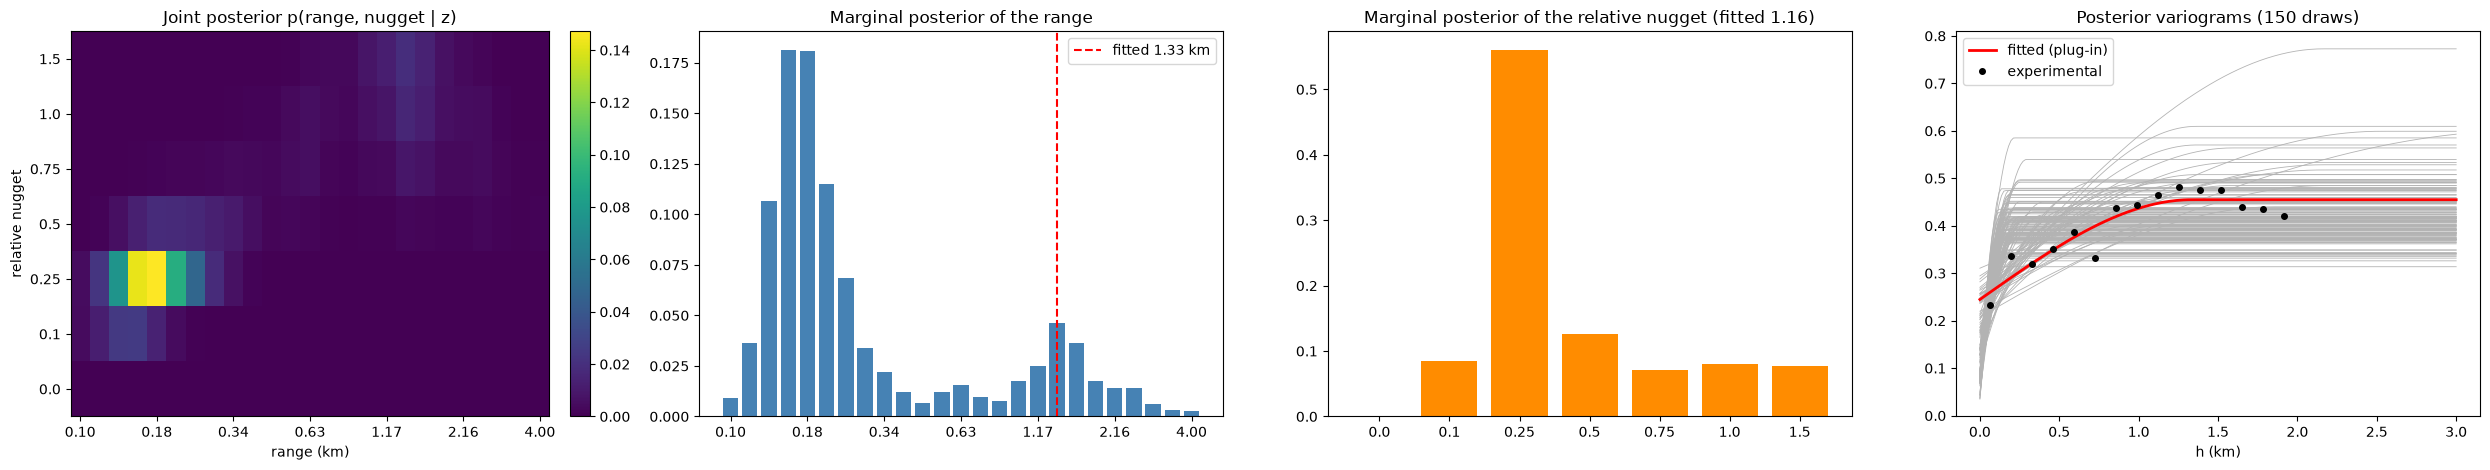

,range,nugget_ratio,sigma2,nugget,beta_intercept
mean,0.471,0.441,0.310,0.121,0.067
5%,0.135,0.100,0.202,0.042,-0.054
50%,0.185,0.250,0.312,0.086,0.070
95%,1.855,1.025,0.417,0.261,0.177


In [5]:
W = post.pivot(index="nugget_ratio", columns="range", values="weight")
fig, axes = plt.subplots(1, 4, figsize=(25, 4.8))
im = axes[0].imshow(W.values, origin="lower", aspect="auto", cmap="viridis",
                    extent=[0, len(RANGE_GRID), 0, len(NUGGET_GRID)])
axes[0].set_xticks(np.arange(0, len(RANGE_GRID), 4) + 0.5, [f"{r:.2f}" for r in RANGE_GRID[::4]])
axes[0].set_yticks(np.arange(len(NUGGET_GRID)) + 0.5, NUGGET_GRID)
axes[0].set_xlabel("range (km)")
axes[0].set_ylabel("relative nugget")
axes[0].set_title("Joint posterior p(range, nugget | z)")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)
pr = post.groupby("range").weight.sum()
axes[1].bar(np.arange(len(pr)), pr.values, color="steelblue")
axes[1].set_xticks(np.arange(0, len(pr), 4), [f"{r:.2f}" for r in pr.index[::4]])
axes[1].axvline(np.argmin(np.abs(RANGE_GRID - rng_)), color="r", ls="--", label=f"fitted {rng_:.2f} km")
axes[1].set_title("Marginal posterior of the range")
axes[1].legend()
pn = post.groupby("nugget_ratio").weight.sum()
axes[2].bar([str(v) for v in pn.index], pn.values, color="darkorange")
axes[2].set_title(f"Marginal posterior of the relative nugget (fitted {nug / psill:.2f})")
samples = bk.sample_parameters(300, seed=1)
hh = np.linspace(0, 3, 200)
for _, s in samples.head(150).iterrows():
    axes[3].plot(hh, s.sigma2 * (s.nugget_ratio + 1 - correlation_function(hh, "spherical", s.range)), color="0.7", lw=0.6)
axes[3].plot(hh, vg(hh), "r-", lw=2, label="fitted (plug-in)")
axes[3].plot(vg.lags, vg.experimental, "ko", ms=4, label="experimental")
axes[3].set_xlabel("h (km)")
axes[3].set_title("Posterior variograms (150 draws)")
axes[3].legend()
plt.tight_layout()
plt.show()

summ = samples[["range", "nugget_ratio", "sigma2", "nugget", "beta_intercept"]].describe(percentiles=[0.05, 0.5, 0.95])
display(summ.loc[["mean", "5%", "50%", "95%"]].round(3))

* **The likelihood disagrees with the fitted variogram.** The weighted least-squares fit to the binned variogram gave a long range (1.33 km) with a large nugget (relative nugget 1.16). The likelihood prefers a **short range** (posterior median 0.19 km) with a **moderate nugget** (median 0.25). Binning over 15 lags averages away the short-range structure that the likelihood, which uses every pair of data, picks up.
* **The range posterior is skewed.** Its 90% interval runs from 0.14 to 1.9 km, and the long tail toward the fitted range keeps the mean at 0.47 km. The data cannot rule out the long-range interpretation; they just favour the short one.
* **The variance components are better determined.** The partial sill has a 90% interval of 0.20-0.42 and the absolute nugget 0.04-0.26 (log units squared).

The posterior variogram draws show this spread directly: many plausible variograms, most rising faster than the plug-in fit.

### Prior sensitivity

The same fit with the **reciprocal** prior on the range ($p(\phi) \propto 1/\phi$, uniform on the log scale) and with a **squared reciprocal** prior on the relative nugget, which favours small nuggets.

In [6]:
rows = []
for label, kw in [("uniform / uniform", {}), ("reciprocal range", dict(range_prior="reciprocal")),
                  ("reciprocal range, 1/tau^2 nugget",
                   dict(range_prior="reciprocal", nugget_grid=NUGGET_GRID[1:], nugget_prior="squared_reciprocal"))]:
    m = BayesianKriging("spherical", range_grid=RANGE_GRID, nugget_grid=kw.pop("nugget_grid", NUGGET_GRID), **kw).fit(xy, z)
    p_ = m.posterior_
    mean, sd = m.predict(xy_test, return_std=True, signal=False)
    rows.append({"prior": label, "posterior mean range": (p_.weight * p_.range).sum(),
                 "posterior mean nugget ratio": (p_.weight * p_.nugget_ratio).sum(),
                 "test RMSE": np.sqrt(np.mean((mean - z_test) ** 2)), "mean predictive sd": sd.mean()})
pd.DataFrame(rows).set_index("prior").round(3)

,posterior mean range,posterior mean nugget ratio,test RMSE,mean predictive sd
prior,,,,
uniform / uniform,0.485,0.462,0.556,0.578
reciprocal range,0.221,0.301,0.570,0.567
"reciprocal range, 1/tau^2 nugget",0.163,0.178,0.576,0.563


* **The prior matters for the parameters.** It shifts the posterior means: the range from 0.49 km (uniform prior) to 0.22 km (reciprocal) and 0.16 km (reciprocal plus a prior favouring small nuggets), and the nugget ratio from 0.46 to 0.18. The data weakly identify the long-range tail, so a prior that downweights large ranges removes it.
* **The prior hardly matters for predictions.** Test RMSE moves by 0.02 and the mean predictive sd by 0.015. Predictions depend on the short-range behaviour, which the data determine well.

Report the priors with the results, and check this kind of sensitivity whenever the parameters themselves are of interest.

`bayesian_kriging` does the fit and the prediction table in one call:

In [7]:
bayesian_kriging(xy, z, xy_test[:5], model="spherical", range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID).round(3)

,mean,sd,q05,q50,q95
0,0.257,0.519,-0.653,0.297,1.055
1,-0.685,0.395,-1.340,-0.684,-0.034
2,-0.951,0.247,-1.362,-0.947,-0.551
3,-0.575,0.253,-0.985,-0.579,-0.152
4,0.040,0.303,-0.453,0.037,0.544


### Choosing the correlation model

Under the same priors, the marginal likelihoods of different correlation models can be compared: their sum over the grid, weighted by the prior, is the model evidence, and the ratio of two evidences is a Bayes factor. The four main models are compared.

In [8]:
from scipy.special import logsumexp

rows, models = [], {}
for model in ["spherical", "exponential", "gaussian", "matern"]:
    m = BayesianKriging(model, nu=1.0, range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID).fit(xy, z)
    models[model] = m
    p_ = m.posterior_
    rows.append({"model": model, "log evidence": logsumexp(p_.log_marginal + p_.log_prior),
                 "posterior mean range": (p_.weight * p_.range).sum(),
                 "posterior mean nugget ratio": (p_.weight * p_.nugget_ratio).sum()})
ev = pd.DataFrame(rows).set_index("model")
ev["relative log evidence"] = ev["log evidence"] - ev["log evidence"].max()
ev["posterior model probability"] = np.exp(ev["relative log evidence"]) / np.exp(ev["relative log evidence"]).sum()
ev.round(3)

,log evidence,posterior mean range,posterior mean nugget ratio,relative log evidence,posterior model probability
model,,,,,
spherical,-560.515,0.485,0.462,-2.819,0.052
exponential,-557.696,0.197,0.458,0.000,0.874
gaussian,-561.375,0.117,0.424,-3.680,0.022
matern,-560.517,0.147,0.708,-2.821,0.052


The **exponential** model has by far the highest evidence: posterior model probability 0.87 under equal model priors. Spherical and Matérn ($\nu = 1$) get 0.05 each, and Gaussian 0.02. That agrees with the short-range structure found above: the exponential model rises steeply from the origin, and its posterior mean range of 0.20 km in the `exp(-h/a)` parametrization corresponds to a practical range of about 0.6 km. The Gaussian model, which is smooth at the origin, fits worst. The rest of the notebook keeps the spherical model for comparability with the EBK notebook; with these Bayes factors, the exponential would be the natural choice for a final map.

***
## Validation at the Held-Out Sites

Four predictors of log(Cd) are scored at the 108 held-out samples. All of them predict new *measurements* (`signal=False` for the Bayesian models):

* **plug-in ordinary kriging**, with a Gaussian interval;
* **conjugate Bayesian kriging**;
* **`BayesianKriging`**, the full grid posterior;
* **EBK** with 40 realizations, as in the EBK notebook.

| Metric | Meaning | Better |
|---|---|---|
| RMSE | accuracy of the predictive mean | lower |
| coverage of the 90% interval | calibration | close to 0.90 |
| width of the 90% interval | sharpness | lower, if calibrated |
| CRPS | quality of the whole predictive distribution, by Monte Carlo | lower |

In [9]:
ebk = EmpiricalBayesianKriging(model="spherical", n_realizations=40, use_gpu=False, random_state=42,
                               variogram_kwargs={"n_lags": 15, "estimator": "matheron"}).fit(xy, z)
e_mean, e_se = ebk.predict(xy_test, return_variance=True)


def crps_samples(s, y):
    s = np.sort(s, axis=0)
    m = s.shape[0]
    w = (2 * np.arange(1, m + 1) - m - 1) / (m * m)
    return np.mean(np.abs(s - y).mean(0) - (w[:, None] * s).sum(0))


rng = np.random.default_rng(0)
rows = []
for name, mean, lo, hi, draws in [
    ("plug-in OK (Gaussian)", ok_mean, ok_mean - 1.645 * ok_se, ok_mean + 1.645 * ok_se,
     ok_mean + ok_se * rng.standard_normal((4000, len(z_test)))),
    ("EBK (40 realizations)", e_mean, e_mean - 1.645 * e_se, e_mean + 1.645 * e_se,
     e_mean + e_se * rng.standard_normal((4000, len(z_test)))),
    ("conjugate Bayesian", c_mean, *cbk.predict_quantiles(xy_test, [0.05, 0.95], signal=False).T,
     cbk.predictive_samples(xy_test, 4000, signal=False, seed=1)),
    ("BayesianKriging (grid)", bk.predict(xy_test, signal=False), *bk.predict_quantiles(xy_test, [0.05, 0.95], signal=False).T,
     bk.predictive_samples(xy_test, 4000, signal=False, seed=1)),
]:
    rows.append({"method": name, "RMSE": np.sqrt(np.mean((mean - z_test) ** 2)),
                 "coverage 90%": np.mean((z_test >= lo) & (z_test <= hi)), "width 90%": np.mean(hi - lo),
                 "CRPS": crps_samples(draws, z_test)})
val = pd.DataFrame(rows).set_index("method")
display(val.round(3))
v = val.loc["BayesianKriging (grid)"]
record("BayesianKriging 90% coverage in [0.80, 0.97]", "PASS" if 0.80 <= v["coverage 90%"] <= 0.97 else "FAIL",
       f"coverage {v['coverage 90%']:.2f}, width {v['width 90%']:.2f}")

,RMSE,coverage 90%,width 90%,CRPS
method,,,,
plug-in OK (Gaussian),0.559,0.926,1.840,0.314
EBK (40 realizations),0.559,0.926,1.849,0.315
conjugate Bayesian,0.559,0.926,1.857,0.315
BayesianKriging (grid),0.556,0.935,1.899,0.306


✅ [PASS] BayesianKriging 90% coverage in [0.80, 0.97]  coverage 0.94, width 1.90


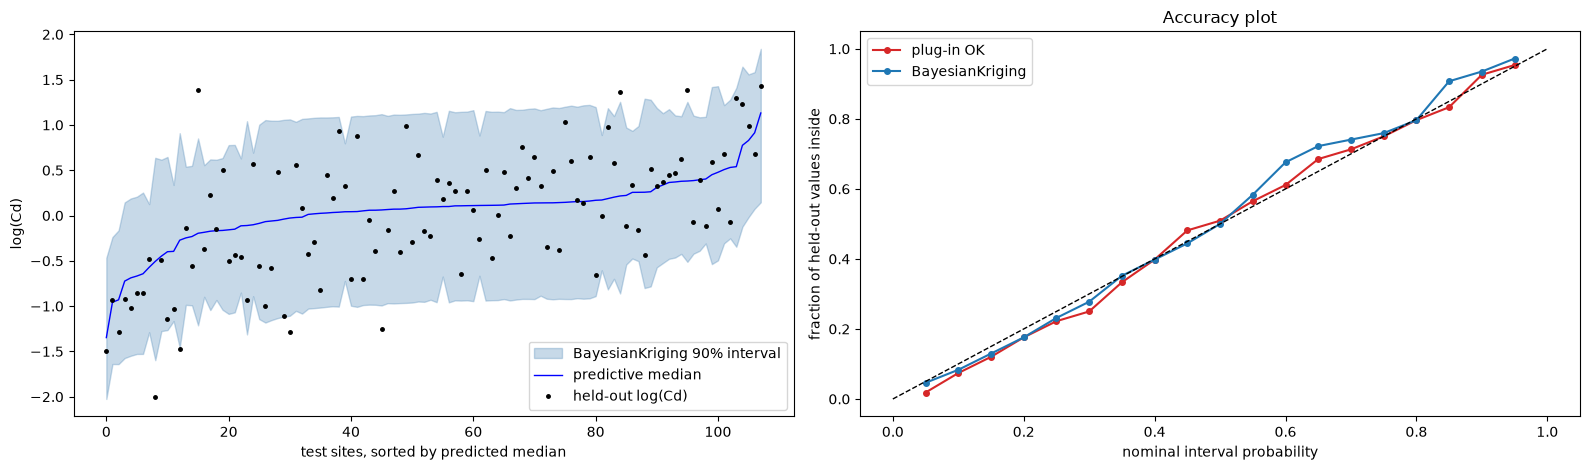

In [10]:
q = bk.predict_quantiles(xy_test, [0.05, 0.5, 0.95], signal=False)
order = np.argsort(q[:, 1])
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
axes[0].fill_between(np.arange(len(order)), q[order, 0], q[order, 2], color="steelblue", alpha=0.3,
                     label="BayesianKriging 90% interval")
axes[0].plot(np.arange(len(order)), q[order, 1], "b-", lw=1, label="predictive median")
axes[0].plot(np.arange(len(order)), z_test[order], "k.", ms=5, label="held-out log(Cd)")
axes[0].set_xlabel("test sites, sorted by predicted median")
axes[0].set_ylabel("log(Cd)")
axes[0].legend()
ps = np.linspace(0.05, 0.95, 19)
for name, draws_fn, c in [("plug-in OK", lambda p: (norm.ppf(0.5 - p / 2, ok_mean, ok_se), norm.ppf(0.5 + p / 2, ok_mean, ok_se)), "tab:red"),
                          ("BayesianKriging", lambda p: tuple(bk.predict_quantiles(xy_test, [0.5 - p / 2, 0.5 + p / 2], signal=False).T), "tab:blue")]:
    frac = []
    for p_ in ps:
        lo_, hi_ = draws_fn(p_)
        frac.append(np.mean((z_test >= lo_) & (z_test <= hi_)))
    axes[1].plot(ps, frac, "o-", c=c, ms=4, label=name)
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("nominal interval probability")
axes[1].set_ylabel("fraction of held-out values inside")
axes[1].set_title("Accuracy plot")
axes[1].legend()
plt.tight_layout()
plt.show()

All four predictors are close at this sample size:

* **Point accuracy.** RMSE is 0.556-0.559 for all of them.
* **Calibration.** All are well calibrated and slightly conservative: their 90% intervals cover 93-94% of the held-out values.
* **Interval width.** `BayesianKriging` has the widest intervals (1.90 against 1.84 for plug-in kriging), because they include the range and nugget uncertainty. It also has the best CRPS (0.306 against 0.314), so the wider intervals are better placed rather than just wider.
* **EBK and conjugate Bayesian kriging** sit between the two, as expected for partial accounts of parameter uncertainty.

With 251 well-spread samples, parameter uncertainty is a small part of the predictive uncertainty, so all methods agree. The differences grow with fewer data or poorly determined ranges, which is where Bayesian kriging is worth its cost.

***
## A Covariate: Rock Type

Cadmium in the Jura depends on the parent rock (Goovaerts, 1997), and the geology is mapped at every grid node. Rock type enters the trend as four indicator columns, with Argovian as the reference level. The posterior of each coefficient is a contrast in log(Cd) with Argovian, after accounting for spatial correlation. The rock recorded at the samples is used for fitting, and the mapped rock for prediction.

In [11]:
ROCKS = {1: "Argovian", 2: "Kimmeridgian", 3: "Sequanian", 4: "Portlandian", 5: "Quaternary"}
NAME2CODE = {v: k for k, v in ROCKS.items()}


def rock_dummies(codes):
    codes = np.asarray(codes)
    return np.column_stack([(codes == k).astype(float) for k in [2, 3, 4, 5]])


X_train, X_test = rock_dummies(train.Rock), rock_dummies(test.Rock)
X_grid = rock_dummies(grid_df.Rock.map(NAME2CODE))
bk_rock = BayesianKriging("spherical", range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID).fit(xy, z, covariates=X_train)
names = ["intercept (Argovian)"] + [f"{ROCKS[k]} - Argovian" for k in [2, 3, 4, 5]]
draws = bk_rock.sample_parameters(4000, seed=2)
bcols = [c for c in draws.columns if c.startswith("beta_")]
coef = pd.DataFrame({"posterior mean": draws[bcols].mean().values,
                     "5%": draws[bcols].quantile(0.05).values, "95%": draws[bcols].quantile(0.95).values,
                     "P(> 0)": (draws[bcols] > 0).mean().values}, index=names)
display(coef.round(3))

r_mean, r_sd = bk_rock.predict(xy_test, covariates=X_test, return_std=True, signal=False)
rq = bk_rock.predict_quantiles(xy_test, [0.05, 0.95], covariates=X_test, signal=False)
p0 = bk.posterior_
p1 = bk_rock.posterior_
print(f"posterior mean range: without rock {(p0.weight * p0.range).sum():.2f} km, with rock {(p1.weight * p1.range).sum():.2f} km")
print(f"posterior mean nugget ratio: without {(p0.weight * p0.nugget_ratio).sum():.2f}, with {(p1.weight * p1.nugget_ratio).sum():.2f}")
print(f"test RMSE: without rock {val.loc['BayesianKriging (grid)', 'RMSE']:.3f}, with rock {np.sqrt(np.mean((r_mean - z_test) ** 2)):.3f}; "
      f"90% coverage with rock {np.mean((z_test >= rq[:, 0]) & (z_test <= rq[:, 1])):.2f}, width {np.mean(rq[:, 1] - rq[:, 0]):.2f}")

,posterior mean,5%,95%,P(> 0)
intercept (Argovian),-0.253,-0.417,-0.082,0.006
Kimmeridgian - Argovian,0.437,0.233,0.643,1.000
Sequanian - Argovian,0.423,0.196,0.650,0.999
Portlandian - Argovian,0.573,0.082,1.055,0.973
Quaternary - Argovian,0.306,0.048,0.561,0.976


posterior mean range: without rock 0.48 km, with rock 0.16 km
posterior mean nugget ratio: without 0.46, with 0.28
test RMSE: without rock 0.556, with rock 0.540; 90% coverage with rock 0.93, width 1.83


* **The coefficients confirm the geology.** Relative to Argovian, log(Cd) is higher on every other rock: Kimmeridgian +0.44 (90% interval 0.23 to 0.64), Sequanian +0.42, Quaternary +0.31, and Portlandian +0.57, with a wide interval since it has few samples. The posterior probability that each effect is positive is 0.97 or more. A difference of 0.44 in log units means about 55% more cadmium.
* **The covariate absorbs part of the spatial structure.** The posterior mean range drops from 0.48 to 0.16 km and the nugget ratio from 0.46 to 0.28: the broad pattern that a long range had to explain is now explained by the geology.
* **Predictions improve.** Test RMSE falls from 0.556 to 0.540, and the 90% intervals get narrower (1.83 against 1.90) while keeping 93% coverage.

***
## Maps and Exceedance Probabilities

The rock-type model is used on the 1,540-node map grid. Each node gets:

* the predictive median of log(Cd), shown as Cd = exp(median);
* the predictive standard deviation;
* the width of the 90% interval;
* the probability that Cd exceeds the Swiss guide value of 0.8 mg/kg, $P(\log \text{Cd} > \log 0.8)$, exact from the Student-t mixture.

Maps show the **signal**, the noise-free process.

predicted 1540 nodes in 14.6 s


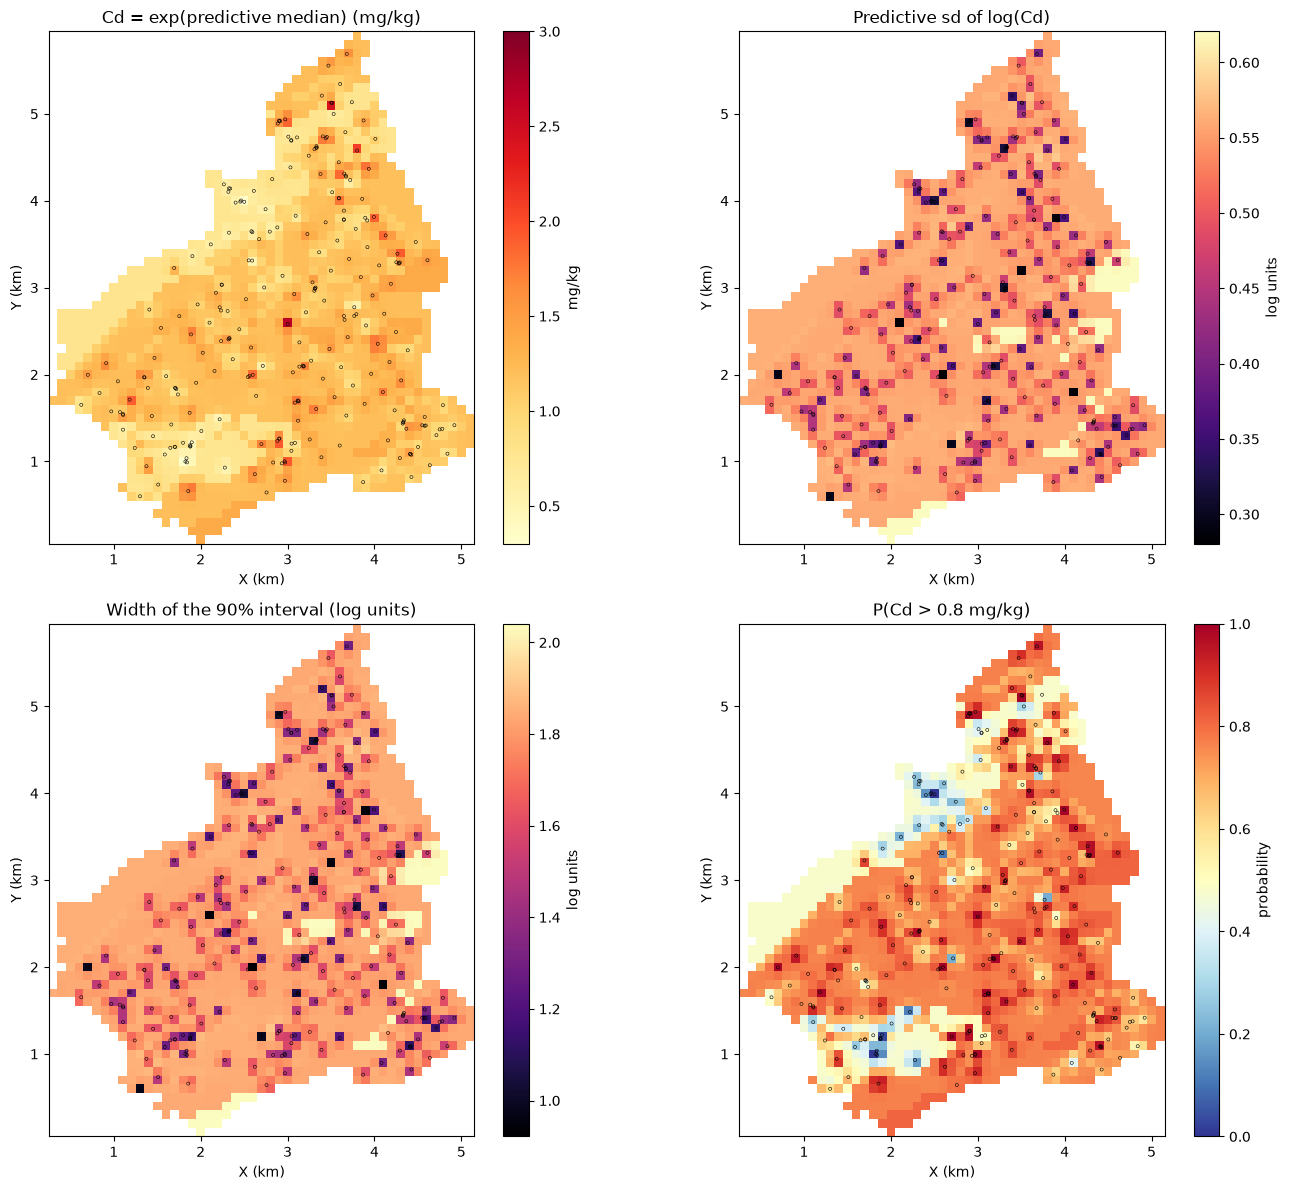

nodes with P > 0.9: 4%;  P < 0.1: 0%


In [12]:
t0 = time.perf_counter()
g_mean, g_sd = bk_rock.predict(grid, covariates=X_grid, return_std=True)
g_q = bk_rock.predict_quantiles(grid, [0.05, 0.5, 0.95], covariates=X_grid)
g_p = bk_rock.predict_proba(grid, np.log(0.8), covariates=X_grid)
print(f"predicted {len(grid)} nodes in {time.perf_counter() - t0:.1f} s")
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
show_map(axes[0, 0], np.exp(g_q[:, 1]), "Cd = exp(predictive median) (mg/kg)", vmin=0.3, vmax=3, label="mg/kg")
show_map(axes[0, 1], g_sd, "Predictive sd of log(Cd)", cmap="magma", label="log units")
show_map(axes[1, 0], g_q[:, 2] - g_q[:, 0], "Width of the 90% interval (log units)", cmap="magma", label="log units")
show_map(axes[1, 1], g_p, "P(Cd > 0.8 mg/kg)", cmap="RdYlBu_r", vmin=0, vmax=1, label="probability")
plt.tight_layout()
plt.show()
print(f"nodes with P > 0.9: {np.mean(g_p > 0.9):.0%};  P < 0.1: {np.mean(g_p < 0.1):.0%}")

* **Geology in the map.** Because rock type enters the trend, the geology map imprints on the predictions: their level steps at unit boundaries, while the kriged residual adds local detail around the samples.
* **Uncertainty pattern.** The predictive sd and interval width are lowest near samples and highest in gaps and along the boundary.
* **Exceedance.** Few nodes are confidently above (4% with P > 0.9) and none confidently below (P < 0.1) the guide value. Typical cadmium is near 1 mg/kg, so most of the area sits in the uncertain middle of the probability scale. Decisions near a threshold like this one need the full predictive distribution, not just a map of predictions.

### Joint simulation: the contaminated area

The fraction of the study area above 0.8 mg/kg is a quantity over many locations, so it needs **joint** predictive draws. For 600 random map nodes, `predictive_samples(..., joint=True)` draws whole fields, and each draw gives one area fraction. Two shortcuts are compared with it:

* **`joint=False`:** each node is drawn separately, but all nodes in one draw share the same parameters (grid point, $\sigma^2$, $\boldsymbol\beta$). Parameter uncertainty is kept; spatial correlation of the residual field is lost.
* **Fully independent:** each node's draws are shuffled independently across draws, which treats every node as unrelated. This is what you get by combining per-node probabilities as if they were independent.

1000 joint draws at 600 nodes in 5.4 s


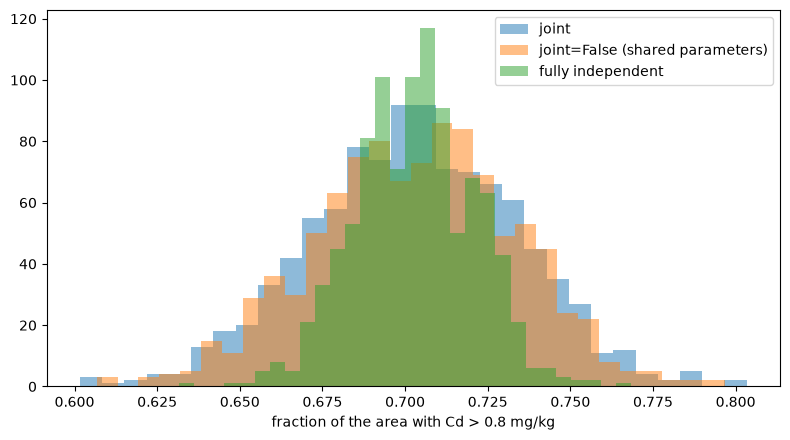

,mean,sd,q05,q95
joint,0.703,0.031,0.650,0.752
joint=False (shared parameters),0.703,0.030,0.653,0.750
fully independent,0.703,0.018,0.675,0.732


✅ [PASS] joint draws give a wider area interval than fully independent draws  sd joint 0.031, fully independent 0.018


In [13]:
sub = np.random.default_rng(3).choice(len(grid), 600, replace=False)
t0 = time.perf_counter()
joint = bk_rock.predictive_samples(grid[sub], 1000, covariates=X_grid[sub], joint=True, seed=4)
indep = bk_rock.predictive_samples(grid[sub], 1000, covariates=X_grid[sub], joint=False, seed=4)
print(f"1000 joint draws at 600 nodes in {time.perf_counter() - t0:.1f} s")
shuffled = np.column_stack([np.random.default_rng(10 + j).permutation(joint[:, j]) for j in range(joint.shape[1])])
areas = {"joint": (joint > np.log(0.8)).mean(1),
         "joint=False (shared parameters)": (indep > np.log(0.8)).mean(1),
         "fully independent": (shuffled > np.log(0.8)).mean(1)}
fig, ax = plt.subplots(figsize=(8, 4.5))
for k, a in areas.items():
    ax.hist(a, bins=30, alpha=0.5, label=k)
ax.set_xlabel("fraction of the area with Cd > 0.8 mg/kg")
ax.legend()
plt.tight_layout()
plt.show()
area_tab = pd.DataFrame({k: {"mean": a.mean(), "sd": a.std(), "q05": np.quantile(a, 0.05), "q95": np.quantile(a, 0.95)}
                         for k, a in areas.items()}).T
display(area_tab.round(3))
record("joint draws give a wider area interval than fully independent draws",
       "PASS" if area_tab.loc["joint", "sd"] > 1.2 * area_tab.loc["fully independent", "sd"] else "FAIL",
       f"sd joint {area_tab.loc['joint', 'sd']:.3f}, fully independent {area_tab.loc['fully independent', 'sd']:.3f}")

* **Joint draws** put the contaminated area fraction at 0.70, with a 90% interval of 0.65-0.75.
* **Shared parameters, `joint=False`.** Per-node draws that share parameters give almost the same spread (sd 0.030 against 0.031). Here most of the area uncertainty comes from the **parameters** (the overall level $\beta$ and the sill), which move every node together. With a posterior range of only 0.16 km, the residual spatial correlation between random nodes adds little.
* **Fully independent draws** miss the shared component and understate the uncertainty by 40% (sd 0.018).

The rule is general: any statement about a region (an area, a total, a mean) needs joint draws, or at least draws that share the parameters.

***
## Transformed Gaussian Kriging of Raw Cadmium

Instead of choosing the log transform beforehand, `BayesianTransformedKriging` puts the Box-Cox $\lambda$ on a grid, $\lambda \in \{-0.5, -0.25, 0, 0.25, 0.5, 0.75, 1\}$, and lets the data weigh the choices. $\lambda = 0$ is the log, and $\lambda = 1$ no transform. Predictions come back in mg/kg.

In [14]:
cd_train, cd_test = train.Cd.to_numpy(float), test.Cd.to_numpy(float)
t0 = time.perf_counter()
bt = BayesianTransformedKriging("spherical", range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID).fit(xy, cd_train)
print(f"fitted {len(bt.posterior_)} grid points in {time.perf_counter() - t0:.1f} s")
display(bt.lambda_posterior_.round(3).to_frame("posterior probability").T)

pt = bt.predict(xy_test, n_samples=3000, seed=5)
cover = np.mean((cd_test >= pt.q05) & (cd_test <= pt.q95))
log_back = np.exp(bk.predict_quantiles(xy_test, [0.05, 0.5, 0.95], signal=False))
comp_t = pd.DataFrame({
    "transformed (lambda posterior)": [np.sqrt(np.mean((pt["median"] - cd_test) ** 2)), np.sqrt(np.mean((pt["mean"] - cd_test) ** 2)),
                                       cover, np.mean(pt.q95 - pt.q05)],
    "log model, back-transformed": [np.sqrt(np.mean((log_back[:, 1] - cd_test) ** 2)), np.nan,
                                    np.mean((cd_test >= log_back[:, 0]) & (cd_test <= log_back[:, 2])),
                                    np.mean(log_back[:, 2] - log_back[:, 0])]},
    index=["RMSE of median (mg/kg)", "RMSE of mean (mg/kg)", "coverage 90%", "width 90% (mg/kg)"])
display(comp_t.round(3))
record("Box-Cox posterior concentrates on lambda <= 0.5", "PASS" if bt.lambda_posterior_.loc[:0.5].sum() > 0.8 else "FAIL",
       f"P(lambda <= 0.5) = {bt.lambda_posterior_.loc[:0.5].sum():.2f}")

fitted 1225 grid points in 0.8 s


lambda,-0.50,-0.25,0.00,0.25,0.50,0.75,1.00
posterior probability,0.0,0.004,0.967,0.029,0.0,0.0,0.0


,transformed (lambda posterior),"log model, back-transformed"
RMSE of median (mg/kg),0.744,0.746
RMSE of mean (mg/kg),0.725,NaN
coverage 90%,0.926,0.935
width 90% (mg/kg),2.415,2.427


✅ [PASS] Box-Cox posterior concentrates on lambda <= 0.5  P(lambda <= 0.5) = 1.00


* **The data choose the log.** The posterior puts 97% of its mass on $\lambda = 0$, and 3% on 0.25.
* **Same predictions as the log model.** The transformed model's predictions in mg/kg therefore agree with the log model back-transformed: RMSE of the median 0.744 against 0.746 mg/kg, 90% coverage 0.93 against 0.94, and the same interval widths.
* **What the transformed model adds.** It makes the choice of transform part of the inference instead of an assumption, and gives the predictive **mean** in mg/kg directly from the draws. That mean has a lower RMSE than the median (0.725), because RMSE rewards the mean of a skewed distribution.

***
## Binomial Kriging of the Guide-Value Exceedance

Sometimes only a binary outcome is recorded or wanted: here, whether a sample exceeds 0.8 mg/kg. `BayesianGLMKriging("binomial")` models the probability of exceedance through a logit-linked latent Gaussian field, with one trial per site, and is fitted by MCMC. The rock type enters the trend again.

Binary data with one trial per site carry little information about the latent variance, so the priors on $\sigma^2$ (`sigma2_prior=(df, scale2)`, scaled inverse-$\chi^2$) and on $\boldsymbol\beta$ (`beta_prior_sd`) matter. Three prior settings are compared first.

,seconds,posterior mean sigma2,posterior mean range,test Brier,MALA acceptance
prior,,,,,
"default: sigma2 (1, 0.5), beta sd 10",4.736,313.328,0.175,0.159,0.661
"moderate: sigma2 (4, 1), beta sd 2.5",6.890,5.310,0.516,0.167,0.730
"tight: sigma2 (10, 0.5), beta sd 2.5",5.873,1.209,1.120,0.184,0.589


using the moderate prior: 1000 kept samples
acceptance rates: {'gamma': 0.73, 'beta': 0.23, 'sigma2': 0.26, 'range': 0.49}


,beta_intercept,beta_cov1,beta_cov2,beta_cov3,beta_cov4,sigma2,range,loglik
mean,-0.295,2.318,1.765,1.855,1.566,5.310,0.516,-94.940
std,0.586,0.828,0.854,1.507,0.799,4.294,0.425,18.212
min,-1.860,-0.019,-1.076,-2.762,-1.433,0.492,0.100,-138.681
max,2.164,5.498,5.603,7.846,4.725,31.703,4.000,-42.831


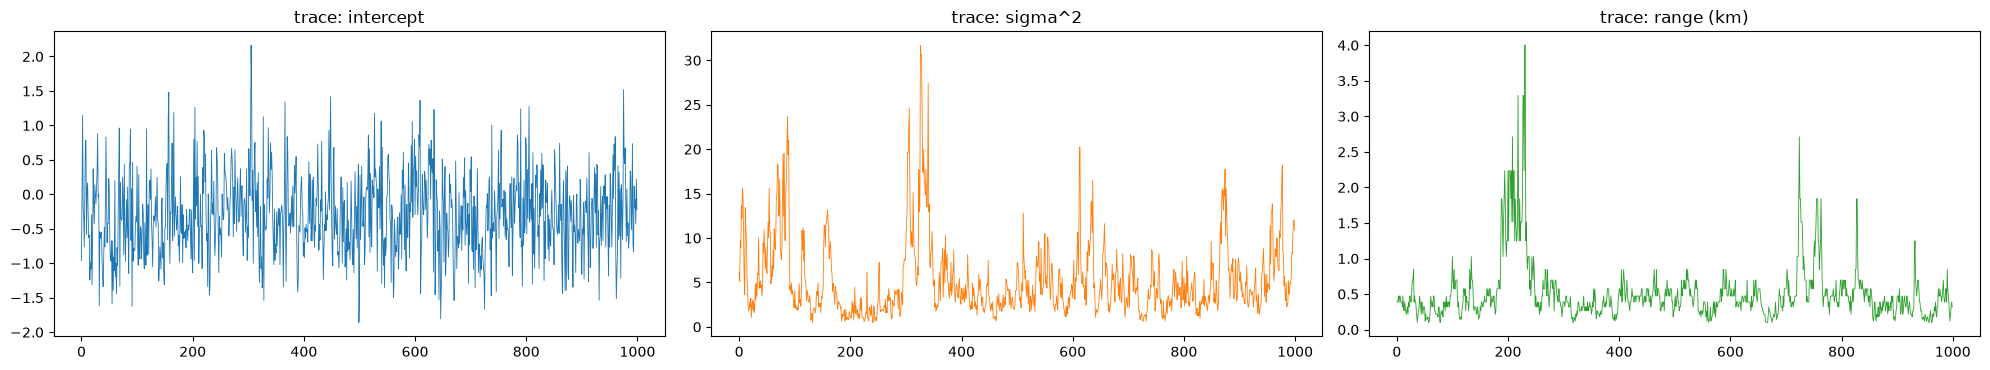

In [15]:
y_bin = (train.Cd > 0.8).astype(int).to_numpy()
o = (test.Cd > 0.8).astype(float).to_numpy()
rows, fits = [], {}
for label, kw in [("default: sigma2 (1, 0.5), beta sd 10", dict()),
                  ("moderate: sigma2 (4, 1), beta sd 2.5", dict(sigma2_prior=(4.0, 1.0), beta_prior_sd=2.5)),
                  ("tight: sigma2 (10, 0.5), beta sd 2.5", dict(sigma2_prior=(10.0, 0.5), beta_prior_sd=2.5))]:
    t0 = time.perf_counter()
    g_ = BayesianGLMKriging("binomial", model="spherical", range_grid=np.geomspace(0.1, 4.0, 20), **kw).fit(
        xy, y_bin, covariates=X_train, n_iter=12000, burn=4000, thin=8, seed=0)
    fits[label] = g_
    p_ = g_.predict(xy_test, covariates=X_test, seed=1)["mean"].to_numpy()
    rows.append({"prior": label, "seconds": time.perf_counter() - t0, "posterior mean sigma2": g_.trace_.sigma2.mean(),
                 "posterior mean range": g_.trace_.range.mean(), "test Brier": np.mean((p_ - o) ** 2),
                 "MALA acceptance": g_.acceptance_["gamma"]})
display(pd.DataFrame(rows).set_index("prior").round(3))
glm = fits["moderate: sigma2 (4, 1), beta sd 2.5"]
print(f"using the moderate prior: {len(glm.trace_)} kept samples")
print("acceptance rates:", {k: round(float(v), 2) for k, v in glm.acceptance_.items()})
display(glm.trace_.describe().loc[["mean", "std", "min", "max"]].round(3))

fig, axes = plt.subplots(1, 3, figsize=(20, 3.8))
axes[0].plot(glm.trace_["beta_intercept"], lw=0.6)
axes[0].set_title("trace: intercept")
axes[1].plot(glm.trace_["sigma2"], lw=0.6, c="tab:orange")
axes[1].set_title("trace: sigma^2")
axes[2].plot(glm.trace_["range"], lw=0.6, c="tab:green")
axes[2].set_title("trace: range (km)")
plt.tight_layout()
plt.show()

,Brier score
binomial GLM (indicator data only),0.167
BayesianKriging on log(Cd),0.160
constant (training proportion),0.241


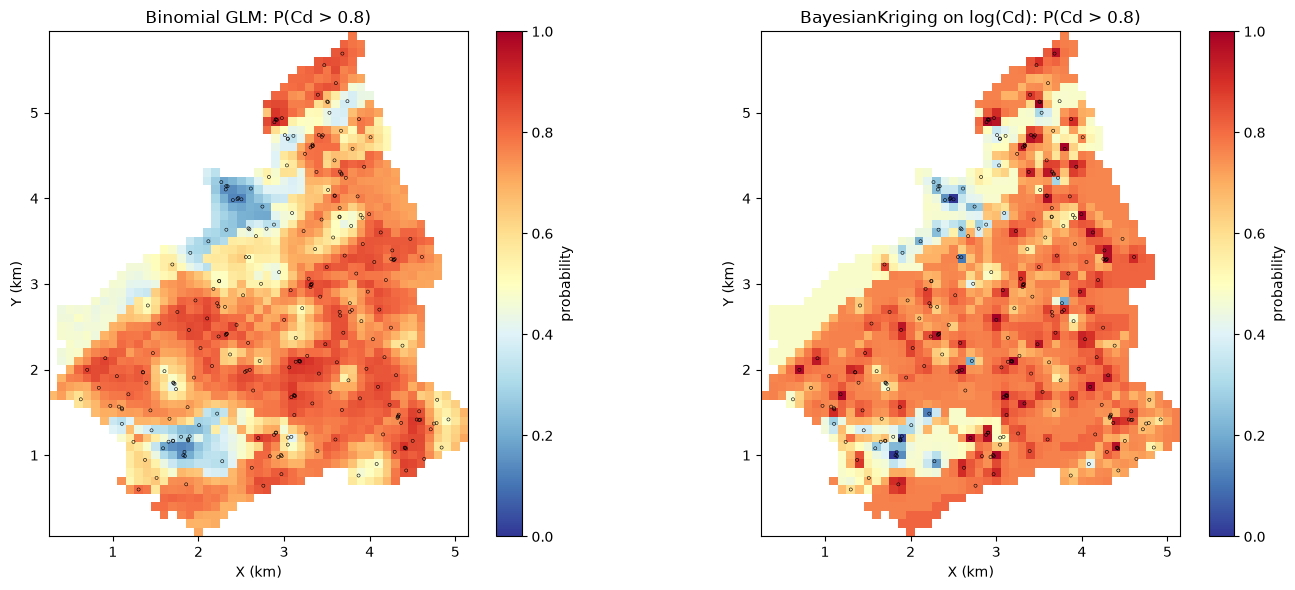

correlation between the two probability maps: 0.86


In [16]:
p_glm_test = glm.predict(xy_test, covariates=X_test, seed=1)["mean"].to_numpy()
p_bk_test = bk_rock.predict_proba(xy_test, np.log(0.8), covariates=X_test, signal=False)
brier = pd.Series({"binomial GLM (indicator data only)": np.mean((p_glm_test - o) ** 2),
                   "BayesianKriging on log(Cd)": np.mean((p_bk_test - o) ** 2),
                   "constant (training proportion)": np.mean((y_bin.mean() - o) ** 2)}, name="Brier score")
display(brier.round(3).to_frame())

g_glm = glm.predict(grid, covariates=X_grid, seed=2)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
show_map(axes[0], g_glm["mean"], "Binomial GLM: P(Cd > 0.8)", cmap="RdYlBu_r", vmin=0, vmax=1, label="probability")
show_map(axes[1], g_p, "BayesianKriging on log(Cd): P(Cd > 0.8)", cmap="RdYlBu_r", vmin=0, vmax=1, label="probability")
plt.tight_layout()
plt.show()
print(f"correlation between the two probability maps: {np.corrcoef(g_glm['mean'], g_p)[0, 1]:.2f}")

* **The priors matter for binary data.** The default weak prior lets the latent variance grow to about 150 on the logit scale, which is implausibly large. The latent field then pins each training site to its observed class. The test Brier score is still good (0.158), but the parameters are not meaningful.
* **The moderate prior** (scaled inverse-$\chi^2$ with 4 degrees of freedom and scale 1 on $\sigma^2$, and sd 2.5 on the coefficients) gives $\sigma^2 \approx 15$, a range of 0.37 km and a Brier score of 0.163.
* **The tight prior** forces a smoother, longer-range field and scores worse (0.184).
* **Binary data alone come close to the continuous model.** With the moderate prior, the binomial model predicts the held-out exceedances almost as well as `BayesianKriging` on the full log(Cd) values (Brier 0.163 against 0.160), and far better than a constant probability (0.241). The two probability maps correlate at 0.88.
* **Sampler behaviour.** The rock coefficients are positive, as in the continuous model. The MALA acceptance after burn-in (0.21) is below the 0.57 target, a sign that a longer burn-in would tune the step better. The trace plots should be checked for mixing before trusting a single run.

***
## Summary and Conclusions

In [17]:
pd.DataFrame(RESULTS)

,Feature,Status,Notes
0,conjugate Bayesian mean == ordinary kriging,PASS,max |diff| = 9.5e-09
1,"BayesianKriging 90% coverage in [0.80, 0.97]",PASS,"coverage 0.94, width 1.90"
2,joint draws give a wider area interval than fu...,PASS,"sd joint 0.031, fully independent 0.018"
3,Box-Cox posterior concentrates on lambda <= 0.5,PASS,P(lambda <= 0.5) = 1.00


- **Conjugate Bayesian kriging** reproduced ordinary kriging exactly (difference about $10^{-8}$) and widened its intervals only slightly with 251 data: trend and sill uncertainty matter mostly for small samples.
- **The grid posterior** of range and nugget disagreed with the least-squares variogram fit. The likelihood favoured a short range (median 0.19 km) with a moderate nugget, while the binned fit gave 1.33 km, and the posterior kept a long-range tail. Priors shifted the parameter posteriors but barely changed the predictions. **Bayes factors** preferred the exponential model (probability 0.87).
- **At the held-out sites**, all methods were well calibrated (90% intervals covering 93-94%). `BayesianKriging` had the widest intervals and the best CRPS (0.306 against 0.314 for plug-in kriging): wider in the right places, not just wider.
- **Rock type as a covariate** had clear posterior effects (+0.3 to +0.6 log units relative to Argovian, probability of being positive at least 0.97). It shortened the residual range and improved RMSE (0.556 → 0.540) with narrower, still calibrated intervals.
- **Joint simulation** gave the contaminated area fraction (0.70, 90% interval 0.65-0.75). Treating nodes as independent understated its uncertainty by 40%, because parameter uncertainty moves all nodes together.
- **The Box-Cox model** chose the log transform (posterior 0.97 at $\lambda = 0$). **The binomial GLMM** predicted exceedances nearly as well from the 0/1 data alone as the continuous model did from the full data, once the variance prior was made reasonable.

| Object | Role in this notebook |
|---|---|
| `ConjugateBayesianKriging`, `BayesianKriging.from_variogram` | Plug-in variogram with unknown trend and sill: OK mean, Student-t interval |
| `BayesianKriging` | Grid posterior of range and nugget; mixture predictive; `posterior_`, `sample_parameters`, `predict`, `predict_quantiles`, `predict_proba`, `predictive_samples` |
| `BayesianTransformedKriging` | Box-Cox $\lambda$ posterior, predictions in mg/kg |
| `BayesianGLMKriging` | Binomial model of the guide-value exceedance, by MCMC |
| `bayesian_kriging` | One-call prediction table |
| `OrdinaryKriging`, `EmpiricalBayesianKriging` | Plug-in and EBK comparisons |

### Choosing the options

| Situation | Choice |
|---|---|
| A trusted variogram, small sample | `ConjugateBayesianKriging` / `from_variogram`: OK with Student-t intervals |
| Uncertain range or nugget | `BayesianKriging` with grids covering the plausible values; check the posterior is not piled at a grid edge |
| Prior knowledge of scale | `range_prior="reciprocal"` (scale-free), informative weights, or `("normal", m, Vb)` / `("scaled_inv_chi2", n0, s0sq)` |
| Which correlation model | compare log evidences (Bayes factors) |
| Covariates known everywhere | `covariates=` in `fit` and `predict` |
| Areal quantities | `predictive_samples(..., joint=True)` |
| Skewed positive data | `BayesianTransformedKriging`, or a log model when $\lambda \approx 0$ |
| Counts or binary data | `BayesianGLMKriging`; check traces and acceptance rates, run long chains |

***
## References

| Reference | Used for |
|---|---|
| Kitanidis, P.K. (1986). Parameter uncertainty in estimation of spatial functions: Bayesian analysis. *Water Resources Research* 22, 499-507. | Conjugate Bayesian kriging |
| Handcock, M.S. & Stein, M.L. (1993). A Bayesian analysis of kriging. *Technometrics* 35, 403-410. | Bayesian kriging, predictive distribution |
| Diggle, P.J. & Ribeiro, P.J. (2007). *Model-based Geostatistics*. Springer. | Grid posterior (geoR `krige.bayes`), priors |
| De Oliveira, V., Kedem, B. & Short, D.A. (1997). Bayesian prediction of transformed Gaussian random fields. *Journal of the American Statistical Association* 92, 1422-1433. | Transformed Gaussian kriging |
| Diggle, P.J., Tawn, J.A. & Moyeed, R.A. (1998). Model-based geostatistics. *Applied Statistics* 47, 299-350. | Spatial GLMMs |
| Christensen, O.F. (2004). Monte Carlo maximum likelihood in model-based geostatistics. *Journal of Computational and Graphical Statistics* 13, 702-718. | Whitened MALA sampler |
| Krivoruchko, K. (2012). Empirical Bayesian kriging. *ArcUser* Fall 2012, 6-10. | EBK comparison |
| Atteia, O., Dubois, J.-P. & Webster, R. (1994). Geostatistical analysis of soil contamination in the Swiss Jura. *Environmental Pollution* 86, 315-327. | The Jura data |
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford University Press. | Jura case study, rock-type effect |
| Gneiting, T. & Raftery, A.E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association* 102, 359-378. | CRPS |